<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

# 11_02 Multi-head attention and Transformer encoder

In this notebook, you will implement the core components of the Transformer encoder architecture, step by step, from scratch using PyTorch.    


### 1. The `MultiHeadSelfAttention` class

In this exercise, you’ll implement **multi-head self-attention**, the core operation of the Transformer.

Each token first generates queries (Q) keys (K), and values (V), which are then used to compute attention across all tokens.

**Steps:**
1. In `__init__`:
   - Create three `nn.Linear` layers for Q, K, and V projections.  
   - Create one output linear layer `W_o` for combining heads.
   - Store useful attributes (`num_heads`, `d_k`, `d_v`).
   - Define the scale factor `self.scale`.

2. In `forward(x)`:
   - Input `x`: tensor of shape `(B, T, d_model)`.
   - Compute Q, K, V = linear projections of `x`.
   - Reshape them to `(B, num_heads, T, d_k)` and `(B, num_heads, T, d_v)`.
   - Compute scaled dot-product attention:
     $$
     \text{scores} = \frac{QK^T}{\sqrt{d_k}}
     $$
   - Apply softmax over the last dimension to get attention weights.
   - Compute attention output = softmax(scores) × V.
   - Concatenate all heads and apply `W_o`.

3. Return the final output tensor `(B, T, d_model)`.

In [16]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt



class MultiHeadSelfAttention(nn.Module):

    def __init__(self, d_model, d_k, d_v, num_heads):
        super(MultiHeadSelfAttention, self).__init__()

        self.num_heads = num_heads
        self.d_k = d_k
        self.d_v = d_v
        self.d_model = d_model

        self.W_Q = nn.Linear(d_model, num_heads * d_k, bias=False)
        self.W_K = nn.Linear(d_model, num_heads * d_k, bias=False)
        self.W_V = nn.Linear(d_model, num_heads * d_v, bias=False)

        self.W_o = nn.Linear(num_heads * d_v, d_model, bias=False)

        self.scale = math.sqrt(d_k)

    def forward(self, x):
        B, T, _ = x.shape

        Q_all = self.W_Q(x)  # (B, T, num_heads * d_k)
        K_all = self.W_K(x)  # (B, T, num_heads * d_k)
        V_all = self.W_V(x)  # (B, T, num_heads * d_v)

        # (B, num_heads, T, d_k or d_v)
        Q = Q_all.view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        K = K_all.view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        V = V_all.view(B, T, self.num_heads, self.d_v).transpose(1, 2)

        scores = (Q @ K.transpose(-2, -1)) / self.scale

        attention_weights = torch.softmax(scores, dim=-1)

        out_heads = (attention_weights @ V) #(B, num_heads, T, d_v)

        # (B, num_heads, T, d_v) a (B, T, num_heads, d_v)
        out_joined = out_heads.permute(0, 2, 1, 3)

        # (B, T, num_heads * d_v)
        out_joined = out_joined.flatten(start_dim=2)
        
        output = self.W_o(out_joined)  # (B, T, d_model)

        return output


In [17]:
modelo = MultiHeadSelfAttention(d_model=512, d_k=64, d_v=64, num_heads=8)


x_prueba = torch.randn(32, 10, 512)

resultado = modelo(x_prueba)

print("Forma de la entrada:", x_prueba.shape)
print("Forma de la salida :", resultado.shape)  


Forma de la entrada: torch.Size([32, 10, 512])
Forma de la salida : torch.Size([32, 10, 512])


### 2. The `SinusoidalPositionalEncoding` class

The sinusoidal positional encoding adds deterministic vectors to token embeddings, allowing the model to infer token order.

**Steps:**
1. In `__init__`:
   - Precompute a `(max_len, d_model)` matrix `pe` where:
     $$
     \text{PE}_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i / d_{model}}}\right)
     $$
     $$
     \text{PE}_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i / d_{model}}}\right)
     $$
   - Register it as a buffer (`self.register_buffer("pe", pe)`) so it’s stored with the model but not trained.

2. In `forward(x)`:
   - Input `x`: tensor of shape `(B, T, d_model)`.
   - Slice the first `T` rows of `pe`.
   - Return `x + pe[:T, :]`.

**Expected behavior:**
- Adds unique positional patterns to embeddings.
- Output shape matches input `(B, T, d_model)`.

In [31]:
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, max_len, d_model):
        super().__init__()

        pe = torch.zeros(max_len, d_model)

        pos = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))


        pe[:, 0::2] = torch.sin(pos * div_term)
        pe[:, 1::2] = torch.cos(pos * div_term)

        self.register_buffer("pe", pe)
        
    def forward(self, x):
        B, T, d_model = x.shape
        return x + self.pe[:T, :]
        

        

In [32]:
# Instantiate module
d_model = 64
max_len = 512
pe_layer = SinusoidalPositionalEncoding(max_len=max_len, d_model=d_model)

x = torch.randn(2, 10, d_model)
out = pe_layer(x)

print("Input shape :", x.shape)  
print("Output shape:", out.shape) 

Input shape : torch.Size([2, 10, 64])
Output shape: torch.Size([2, 10, 64])


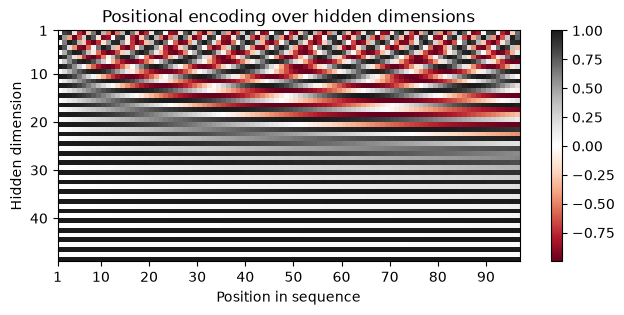

In [33]:
encod_block = SinusoidalPositionalEncoding(d_model=48, max_len=96)
pe = encod_block.pe.squeeze().T.cpu().numpy()

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,3))
pos = ax.imshow(pe, cmap="RdGy", extent=(1,pe.shape[1]+1,pe.shape[0]+1,1))
fig.colorbar(pos, ax=ax)
ax.set_xlabel("Position in sequence")
ax.set_ylabel("Hidden dimension")
ax.set_title("Positional encoding over hidden dimensions")
ax.set_xticks([1]+[i*10 for i in range(1,1+pe.shape[1]//10)])
ax.set_yticks([1]+[i*10 for i in range(1,1+pe.shape[0]//10)])
plt.show()

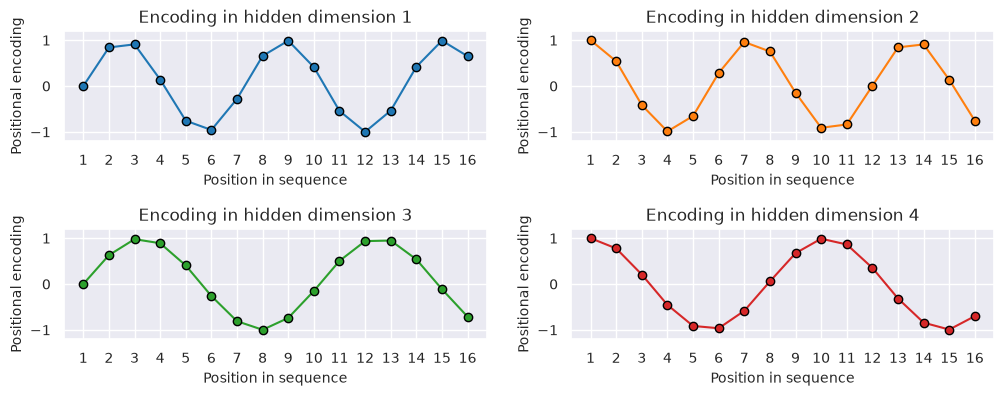

In [34]:
import seaborn as sns
import numpy as np
sns.set_theme()
fig, ax = plt.subplots(2, 2, figsize=(12,4))
ax = [a for a_list in ax for a in a_list]
for i in range(len(ax)):
    ax[i].plot(np.arange(1,17), pe[i,:16], color=f'C{i}', marker="o", markersize=6, markeredgecolor="black")
    ax[i].set_title(f"Encoding in hidden dimension {i+1}")
    ax[i].set_xlabel("Position in sequence", fontsize=10)
    ax[i].set_ylabel("Positional encoding", fontsize=10)
    ax[i].set_xticks(np.arange(1,17))
    ax[i].tick_params(axis='both', which='major', labelsize=10)
    ax[i].tick_params(axis='both', which='minor', labelsize=8)
    ax[i].set_ylim(-1.2, 1.2)
fig.subplots_adjust(hspace=0.8)
sns.reset_orig()
plt.show()

### 3. The `LearnedPositionalEncoding` class

Instead of using fixed sinusoidal values, we can let the model **learn** position embeddings during training.

**Steps:**
1. In `__init__`:
   - Create an `nn.Embedding(max_len, d_model)` called `self.pos_embedding`.
   - Initialize its weights (optionally) near zero:
     ```python
     nn.init.normal_(self.pos_embedding.weight, mean=0.0, std=0.02)
     ```

2. In `forward(x)`:
   - Input `x`: tensor of shape `(B, T, d_model)`.
   - Create a position index tensor `[0, 1, ..., T-1]` on the same device as `x`.
   - Look up position vectors: `self.pos_embedding(positions)`.
   - Return `x + pos_vectors`.

**Expected behavior:**
- Produces a learnable position representation for each index.
- Output shape `(B, T, d_model)`.


In [41]:
class LearnedPositionalEncoding(nn.Module):
    def __init__(self, max_len, d_model):
        super().__init__()
        self.pos_embedding = nn.Embedding(max_len, d_model)
        nn.init.normal_(self.pos_embedding.weight, mean=0.0, std=0.02)

        
    def forward(self, x):
        B, T, d_model = x.shape
        
        positions = torch.arange(0, T, device=x.device)
        
        pos_vectors = self.pos_embedding(positions)      
        return x + pos_vectors

        

In [42]:
max_len = 512
d_model = 64

modelo = LearnedPositionalEncoding(max_len=max_len, d_model=d_model)
x_prueba = torch.randn(2, 10, d_model)

resultado = modelo(x_prueba)

print("Forma de la entrada:", x_prueba.shape)
print("Forma de la salida :", resultado.shape)

Forma de la entrada: torch.Size([2, 10, 64])
Forma de la salida : torch.Size([2, 10, 64])


### 4. The `AddNorm` class

Each sublayer in a Transformer block uses:
- A residual connection (`x + sublayer_output`)
- A LayerNorm to stabilize training

**Two common variants:**
- **Pre-Norm:** Normalize first → apply sublayer → add residual.  
- **Post-Norm:** Apply sublayer → add residual → normalize.

**Steps:**
1. In `__init__`:
   - Create `nn.LayerNorm(d_model)`. [More information](https://docs.pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html)
   - Store `pre_norm` flag (boolean).

2. In `forward(x, sublayer)`:
   - If `pre_norm`:
     ```python
     out = sublayer(self.norm(x))
     return ...
     ```
   - Else:
     ```python
     out = sublayer(x)
     return ...
     ```

**Expected behavior:**
- Input and output shapes: `(B, T, d_model)`.
- Acts as a wrapper around another layer (attention or feedforward).

In [49]:
class AddNorm(nn.Module):
    def __init__(self, d_model, pre_norm):
        super().__init__()
        self.norm = nn.LayerNorm(d_model)
        self.pre_norm = pre_norm

    def forward(self, x, sublayer):
        if self.pre_norm:
            out = sublayer(self.norm(x))
            return x + out
        else:
            out = sublayer(x)
            return self.norm(x + out)

        

In [50]:
d_model = 64
sublayer = nn.Linear(d_model, d_model)

x = torch.randn(2, 10, d_model) 

add_norm_pre = AddNorm(d_model=d_model, pre_norm=True)
add_norm_post = AddNorm(d_model=d_model, pre_norm=False)

# Forward passes
out_pre = add_norm_pre(x, sublayer)
out_post = add_norm_post(x, sublayer)

print("Input shape   :", x.shape)
print("Pre-Norm out  :", out_pre.shape)
print("Post-Norm out :", out_post.shape)

Input shape   : torch.Size([2, 10, 64])
Pre-Norm out  : torch.Size([2, 10, 64])
Post-Norm out : torch.Size([2, 10, 64])


### 5. The `FFN` class

This layer applies the same MLP independently at each position:
$$
\text{FFN}(x) = \text{Linear}(d_{model} \to d_{ff}) \to \text{Activation} \to \text{Linear}(d_{ff} \to d_{model})
$$

**Steps:**
1. In `__init__`:
   - Create the required Linear layers.
   - Choose activation: `"relu"` or `"gelu"`.

2. In `forward(x)`:
   - Implement the forward method


In [56]:
class FFN(nn.Module):
    def __init__(self, d_model, d_ff, activation):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)
        
        if activation.lower() == "relu":
            self.activation = nn.ReLU()
        elif activation.lower() == "gelu":
            self.activation = nn.GELU()
        else:
            raise ValueError(f"Unsupported activation: {activation}. Choose 'relu' or 'gelu'.")

    def forward(self, x):
        return self.fc2(self.activation(self.fc1(x)))

In [57]:
d_model = 64
d_ff = 256 

ffn_layer = FFN(d_model=d_model, d_ff=d_ff, activation="gelu")

x = torch.randn(2, 10, d_model)

out = ffn_layer(x)

print("Input shape :", x.shape)   
print("Output shape:", out.shape) 

Input shape : torch.Size([2, 10, 64])
Output shape: torch.Size([2, 10, 64])


### 6. The `EncoderLayer` class

Each encoder layer performs:
1. Multi-head self-attention
2. Feedforward network  
Each wrapped with Add&Norm.

**Steps:**
1. In `__init__`:
   - Create a `MultiHeadSelfAttention` instance.
   - Create an `AddNorm` wrapper for attention.
   - Create a `FFN` and a second `AddNorm`.

2. In `forward(x)`:
   - Input: `x` of shape `(B, T, d_model)`
   - Perform the following steps **in order**:
     1. **Attention block**  
        - Optionally apply LayerNorm first (if using *pre-norm*).  
        - Compute self-attention output → dropout → add residual → normalize (if *post-norm*).  
     2. **Feedforward block**  
        - Repeat the same Add&Norm pattern: FFN → dropout → residual → (optional normalization).
   - Return the transformed tensor `(B, T, d_model)`.



In [58]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, d_k, d_v, num_heads, prenorm, d_ff, activation):
        super().__init__()

        self.self_attn = MultiHeadSelfAttention(d_model, d_k, d_v, num_heads)
        
        self.add_norm_1 = AddNorm(d_model, prenorm)
        
        self.ffn = FFN(d_model, d_ff, activation)
        self.add_norm_2 = AddNorm(d_model, prenorm)

    def forward(self, x):
        x = self.add_norm_1(x, self.self_attn)
        x = self.add_norm_2(x, self.ffn)

        return x
        


In [60]:
encoder_layer = EncoderLayer(d_model=64, d_k=64, d_v=64, num_heads=8, prenorm=True, d_ff=256, activation="gelu")

x_prueba = torch.randn(2, 10, 64)
resultado = encoder_layer(x_prueba)

print("Forma de la entrada:", x_prueba.shape)
print("Forma de la salida :", resultado.shape)

Forma de la entrada: torch.Size([2, 10, 64])
Forma de la salida : torch.Size([2, 10, 64])


### 7. The `Encoder` class

Now, assemble everything into the full Transformer encoder.

**Steps:**
1. In `__init__`:
   - Create either a `SinusoidalPositionalEncoding` or a learned embedding table for positions.
   - Stack `num_layers` instances of `EncoderLayer` in an `nn.ModuleList`.

2. In `forward(x)`:
   - Input: `(B, T, d_model)` token embeddings.
   - Add positional information (sinusoidal or learned).
   - Pass through each encoder layer in sequence.
   - Return final encoder output `(B, T, d_model)`.


In [61]:
class Encoder(nn.Module):
    def __init__(self, d_model, d_k, d_v, num_heads, num_layers, d_ff, max_len, prenorm, activation, positional_encoding_type):
        super().__init__()

        if positional_encoding_type == "sinusoidal":
            self.pos_encoder = SinusoidalPositionalEncoding(max_len=max_len, d_model=d_model)
        elif positional_encoding_type == "learned":
            self.pos_encoder = LearnedPositionalEncoding(max_len=max_len, d_model=d_model)
        else:
            raise ValueError("positional_encoding_type must be 'sinusoidal' or 'learned'")

        self.layers = nn.ModuleList([EncoderLayer(d_model=d_model,d_k=d_k,d_v=d_v,num_heads=num_heads,prenorm=prenorm,d_ff=d_ff,activation=activation)for _ in range(num_layers)])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, d_model = x.shape
        x = self.pos_encoder(x)
        for layer in self.layers:
            x = layer(x)
        return x

### 8. Test Your Transformer Encoder

Now that you’ve implemented all the components, it’s time to verify your encoder works end-to-end!

This test will:
- Create a small random input sequence.
- Pass it through your `Encoder`.
- Print the output shape and confirm it matches expectations.

**Your task:**
1. Run the following code (don’t modify it).
2. Verify that it runs **without errors** and prints an output shape `(T, d_model)`.

---

```python
import torch

# Define toy settings
T = 5          # sequence length
d_model = 16   # embedding size
num_heads = 4
d_ff = 32
num_layers = 2

# Create a random input tensor (like token embeddings)
x = torch.randn(T, d_model)

# Initialize your encoder
encoder = Encoder(
    d_model=d_model,
    num_layers=num_layers,
    num_heads=num_heads,
    d_ff=d_ff,
    learned_positional=False,   # change to True to test learned encoding
)

# Run a forward pass
with torch.no_grad():
    output = encoder(x)

print("✅ Encoder output shape:", output.shape)
print("Expected shape:", (T, d_model))


In [62]:
import torch

# Settings
T = 5          # sequence length
d_model = 16   # embedding size
num_heads = 4
d_ff = 32
num_layers = 2

# Create a random input tensor WITH batch dimension (B=1, T=5, d_model=16)
x = torch.randn(1, T, d_model)

# Initialize your encoder with your parameter names
encoder = Encoder(
    d_model=d_model,
    d_k=d_model // num_heads,  # 16 // 4 = 4
    d_v=d_model // num_heads,  # 16 // 4 = 4
    num_heads=num_heads,
    num_layers=num_layers,
    d_ff=d_ff,
    max_len=512,
    prenorm=True,
    activation="gelu",
    positional_encoding_type="sinusoidal"  # 'sinusoidal' or 'learned'
)

# Run a forward pass
with torch.no_grad():
    output = encoder(x)

print("✅ Encoder output shape:", output.shape)
print("Expected shape       :", (1, T, d_model))

✅ Encoder output shape: torch.Size([1, 5, 16])
Expected shape       : (1, 5, 16)
